In [1]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import from utils
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from utils.plotting import PALETTE, plot_pmf, set_style

# Apply standard style across all plots
set_style()


# Bernoulli Distribution: The Fundamental Atomic Binary Trial

## 1. Intuition & Motivation

Almost every complex discrete distribution begins with a single, binary question:
*Did an event happen, or did it not?*

- Did the user click the ad (1) or scroll past (0)?
- Did the patient recover (1) or not (0)?
- Did the machine component fail (1) or remain operational (0)?
- Did the email test positive for spam (1) or ham (0)?

The **Bernoulli distribution** is the simplest possible probability distribution. It models a single trial with exactly two outcomes: **Success (1)** with probability $p$, and **Failure (0)** with probability $q = 1 - p$.

It is the atomic building block of probability:
- Summing $n$ independent Bernoulli trials gives a **Binomial** distribution.
- Counting how many Bernoulli failures occur before the first success gives a **Geometric** distribution.


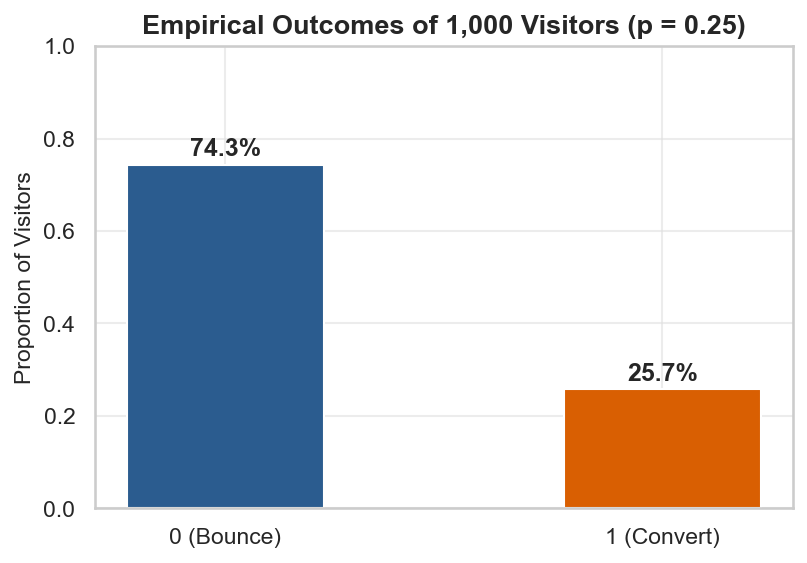

In [2]:
# Parameters: Single visitor conversion rate
p_convert = 0.25
n_visitors = 1000

# Seed for reproducibility
rng = np.random.default_rng(seed=42)

# Generate 1,000 independent binary outcomes (0 = Bounce, 1 = Converted)
visitor_outcomes = rng.binomial(n=1, p=p_convert, size=n_visitors)

# Compute observed frequencies
unique, counts = np.unique(visitor_outcomes, return_counts=True)
proportions = counts / n_visitors

# Plot empirical conversion vs bounce
plt.figure(figsize=(6, 4))
bars = plt.bar(
    ["0 (Bounce)", "1 (Convert)"],
    proportions,
    color=[PALETTE["primary"], PALETTE["secondary"]],
    width=0.45,
)
plt.title(f"Empirical Outcomes of {n_visitors:,} Visitors (p = {p_convert})")
plt.ylabel("Proportion of Visitors")
plt.ylim(0, 1.0)

# Add exact percentage labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 0.02,
        f"{height * 100:.1f}%",
        ha="center",
        weight="bold",
    )

plt.show()


## 2. Mathematical Definition

A random variable $X$ follows a Bernoulli distribution with success probability $p$, written:
$$X \sim \text{Bernoulli}(p)$$

### Parameter & Support
- **$p \in [0, 1]$**: Probability of success ($q = 1 - p$ is failure probability).
- **Support**: Exactly two discrete values: $k \in \{0, 1\}$.

### Probability Mass Function (PMF)
The PMF can be written as a piecewise function:
$$P(X = k) = \begin{cases} 1 - p & \text{if } k = 0 \\ p & \text{if } k = 1 \end{cases}$$

Or more elegantly as a single compact algebraic expression:
$$P(X = k) = p^k (1 - p)^{1 - k} \quad \text{for } k \in \{0, 1\}$$
*(Notice that when $k = 1$, $p^1(1-p)^0 = p$; when $k = 0$, $p^0(1-p)^1 = 1 - p$.)*

### Cumulative Distribution Function (CDF)
The CDF accumulates probability mass across the real number line:
$$F(x) = P(X \le x) = \begin{cases} 0 & \text{if } x < 0 \\ 1 - p & \text{if } 0 \le x < 1 \\ 1 & \text{if } x \ge 1 \end{cases}$$


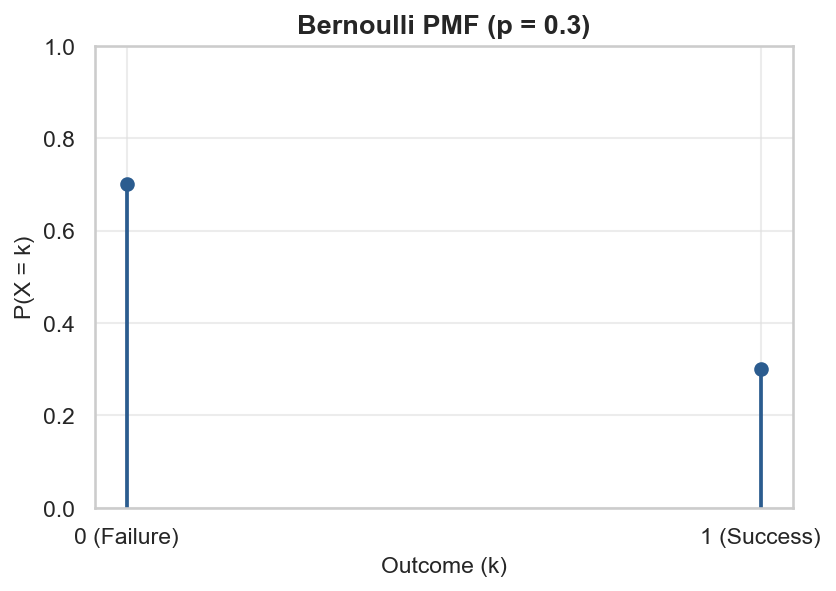

In [3]:
# Parameter
p = 0.3
k_support = np.array([0, 1])

# Theoretical PMF: [P(X=0), P(X=1)]
pmf_values = stats.bernoulli.pmf(k_support, p)

# Plot PMF using our shared helper
fig, ax = plt.subplots(figsize=(6, 4))
plot_pmf(
    k_support,
    pmf_values,
    title=f"Bernoulli PMF (p = {p})",
    xlabel="Outcome (k)",
    ylabel="P(X = k)",
    ax=ax,
)
ax.set_xticks([0, 1])
ax.set_xticklabels(["0 (Failure)", "1 (Success)"])
ax.set_ylim(0, 1.0)
plt.show()


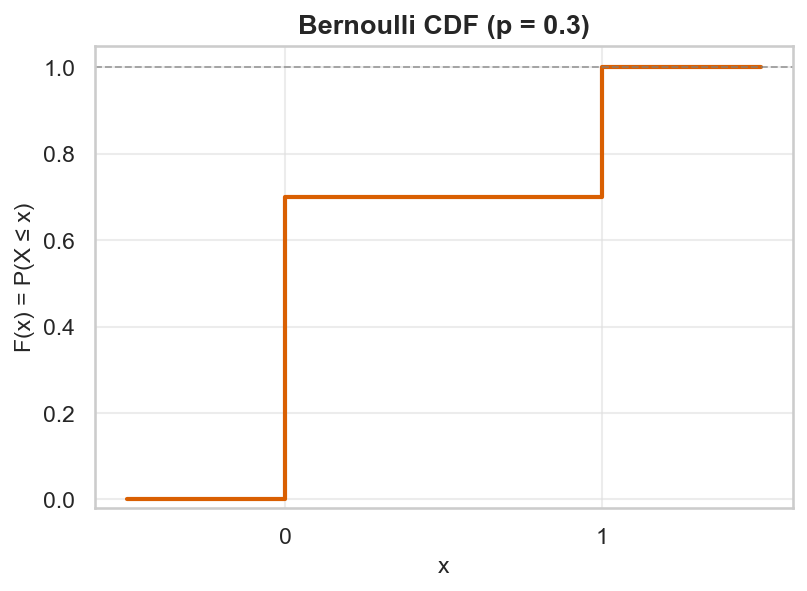

In [4]:
from utils.plotting import plot_cdf

# Define evaluation points spanning across -0.5 to 1.5
x_cdf = np.array([-0.5, 0.0, 0.999, 1.0, 1.5])
cdf_values = stats.bernoulli.cdf(x_cdf, p)

fig, ax = plt.subplots(figsize=(6, 4))
plot_cdf(
    x_cdf,
    cdf_values,
    is_discrete=True,
    title=f"Bernoulli CDF (p = {p})",
    xlabel="x",
    ylabel="F(x) = P(X ≤ x)",
    ax=ax,
)
ax.set_xticks([0, 1])
plt.show()


## 3. Key Theoretical Properties

For $X \sim \text{Bernoulli}(p)$, its shape and properties are defined by its **moments**:

### 1. Expected Value (Mean): $\mathbb{E}[X] = \mu$
$$\mu = 0 \cdot (1 - p) + 1 \cdot p = p$$
The mean is simply the probability of success.

### 2. Variance & Standard Deviation: $\text{Var}(X) = \sigma^2$
$$\sigma^2 = \mathbb{E}[X^2] - (\mathbb{E}[X])^2 = (0^2(1 - p) + 1^2 p) - p^2 = p - p^2 = p(1 - p)$$
$$\sigma = \sqrt{p(1 - p)}$$
Variance reaches its theoretical maximum of $0.25$ when $p = 0.5$ (maximum unpredictability).

### 3. Skewness: $\gamma_1$
$$\gamma_1 = \frac{1 - 2p}{\sqrt{p(1 - p)}}$$
- If $p = 0.5 \implies \gamma_1 = 0$ (symmetric).
- If $p < 0.5 \implies \gamma_1 > 0$ (right-skewed / positive tail towards rare 1s).
- If $p > 0.5 \implies \gamma_1 < 0$ (left-skewed / negative tail towards rare 0s).

### 4. Excess Kurtosis: $\gamma_2$
$$\gamma_2 = \frac{1 - 6p(1 - p)}{p(1 - p)} = \frac{1}{p(1 - p)} - 6$$
At $p = 0.5$, $\gamma_2 = -2$ (a very flat, bimodal distribution with no central peak).


In [5]:
# Choose an asymmetrical parameter
p_test = 0.3

# Analytical calculations
mu_theory = p_test
var_theory = p_test * (1 - p_test)
std_theory = np.sqrt(var_theory)
skew_theory = (1 - 2 * p_test) / np.sqrt(p_test * (1 - p_test))
kurt_theory = (1 - 6 * p_test * (1 - p_test)) / (p_test * (1 - p_test))

# SciPy calculation
mu_sp, var_sp, skew_sp, kurt_sp = stats.bernoulli.stats(p_test, moments="mvsk")

print(f"Moment               | Analytical |   SciPy")
print("-" * 46)
print(f"Mean (μ)             | {mu_theory:10.4f} | {float(mu_sp):10.4f}")
print(f"Variance (σ²)        | {var_theory:10.4f} | {float(var_sp):10.4f}")
print(f"Std Deviation (σ)    | {std_theory:10.4f} | {np.sqrt(float(var_sp)):10.4f}")
print(f"Skewness (γ₁)        | {skew_theory:10.4f} | {float(skew_sp):10.4f}")
print(f"Excess Kurtosis (γ₂) | {kurt_theory:10.4f} | {float(kurt_sp):10.4f}")


Moment               | Analytical |   SciPy
----------------------------------------------
Mean (μ)             |     0.3000 |     0.3000
Variance (σ²)        |     0.2100 |     0.2100
Std Deviation (σ)    |     0.4583 |     0.4583
Skewness (γ₁)        |     0.8729 |     0.8729
Excess Kurtosis (γ₂) |    -1.2381 |    -1.2381


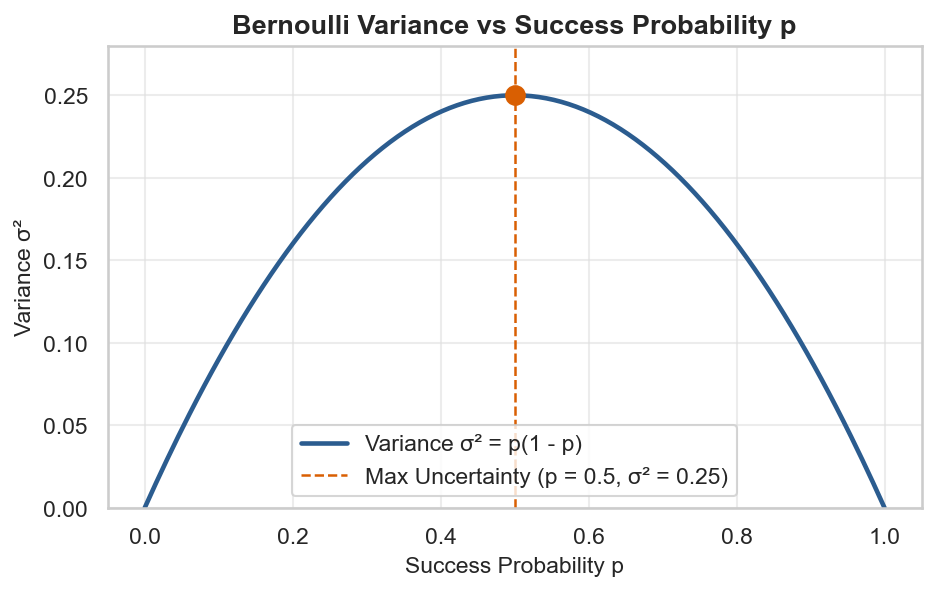

In [6]:
# Evaluate p over full range [0, 1]
p_axis = np.linspace(0, 1, 200)
var_curve = p_axis * (1 - p_axis)

plt.figure(figsize=(7, 4))
plt.plot(
    p_axis,
    var_curve,
    color=PALETTE["primary"],
    linewidth=2.2,
    label="Variance σ² = p(1 - p)",
)

# Highlight maximum uncertainty point
max_p = 0.5
max_var = 0.25
plt.scatter([max_p], [max_var], color=PALETTE["secondary"], s=80, zorder=5)
plt.axvline(
    max_p,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=1.2,
    label="Max Uncertainty (p = 0.5, σ² = 0.25)",
)

plt.title("Bernoulli Variance vs Success Probability p")
plt.xlabel("Success Probability p")
plt.ylabel("Variance σ²")
plt.ylim(0, 0.28)
plt.legend(frameon=True)
plt.show()


## 4. Parameter Variation

Because the Bernoulli distribution has only one parameter, $p$, every characteristic of the distribution—its mean, variance, and skewness—is strictly a function of $p$:

1. **Rare Success ($p < 0.5$, e.g., $p = 0.1$ or $0.2$)**:
   - Most mass concentrates on $0$.
   - The distribution is **positively skewed** ($\gamma_1 > 0$): the rare outcome ($1$) acts as an outlier to the right.
2. **Equiprobable / Maximum Uncertainty ($p = 0.5$)**:
   - Exactly equal mass on $0$ and $1$ ($0.5$ each).
   - Perfectly **symmetric** ($\gamma_1 = 0$).
3. **Frequent Success ($p > 0.5$, e.g., $p = 0.8$ or $0.9$)**:
   - Most mass concentrates on $1$.
   - The distribution is **negatively skewed** ($\gamma_1 < 0$): the rare outcome ($0$) acts as an outlier to the left.


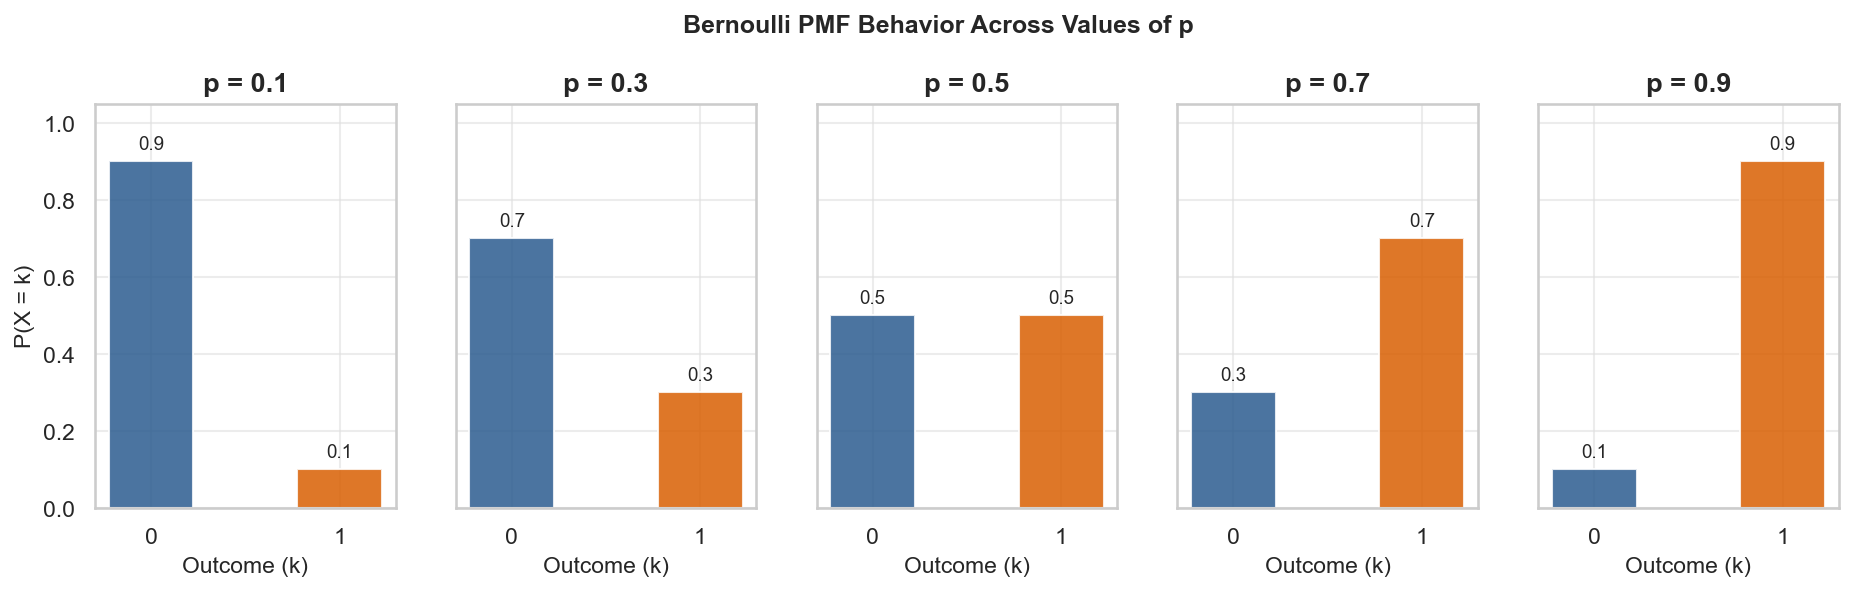

In [7]:
p_values = [0.1, 0.3, 0.5, 0.7, 0.9]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), sharey=True)

for ax, p_val in zip(axes, p_values):
    probs = [1 - p_val, p_val]
    bars = ax.bar(
        [0, 1],
        probs,
        color=[PALETTE["primary"], PALETTE["secondary"]],
        width=0.45,
        alpha=0.85,
    )

    ax.set_title(f"p = {p_val}")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["0", "1"])
    ax.set_xlabel("Outcome (k)")
    ax.set_ylim(0, 1.05)

    # Label heights
    for b in bars:
        h = b.get_height()
        ax.text(
            b.get_x() + b.get_width() / 2,
            h + 0.03,
            f"{h:.1f}",
            ha="center",
            fontsize=9,
        )

axes[0].set_ylabel("P(X = k)")
plt.suptitle(
    "Bernoulli PMF Behavior Across Values of p", y=1.05, weight="bold", fontsize=12
)
plt.show()


C:\Users\Shashank\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


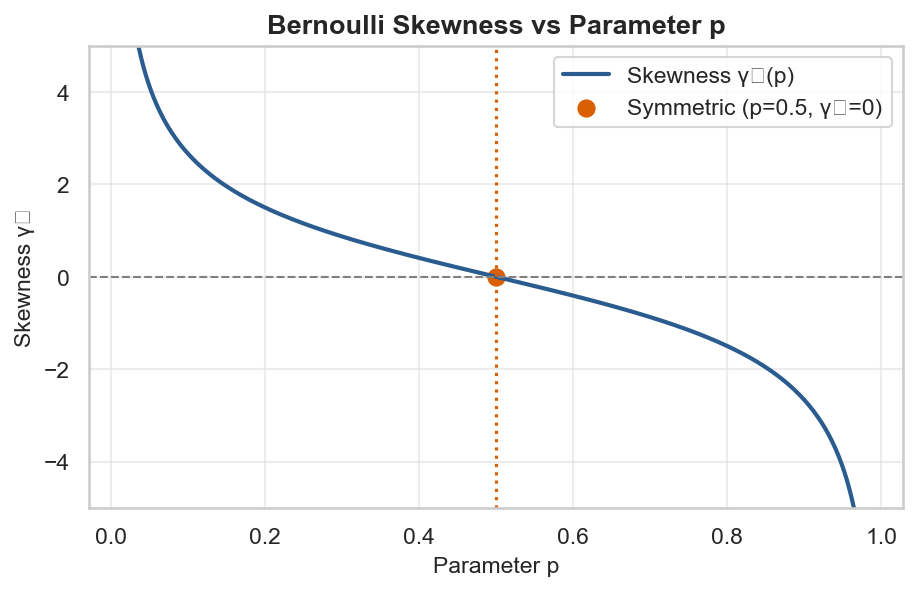

In [8]:
# Avoid exact 0 and 1 where denominator is 0
p_domain = np.linspace(0.02, 0.98, 300)
skew_curve = (1 - 2 * p_domain) / np.sqrt(p_domain * (1 - p_domain))

plt.figure(figsize=(7, 4))
plt.plot(
    p_domain,
    skew_curve,
    color=PALETTE["primary"],
    linewidth=2,
    label="Skewness γ₁(p)",
)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.axvline(0.5, color=PALETTE["secondary"], linestyle=":", linewidth=1.5)
plt.scatter([0.5], [0], color=PALETTE["secondary"], s=60, label="Symmetric (p=0.5, γ₁=0)")

plt.title("Bernoulli Skewness vs Parameter p")
plt.xlabel("Parameter p")
plt.ylabel("Skewness γ₁")
plt.ylim(-5, 5)
plt.legend(frameon=True)
plt.show()


## 5. Simulation & Law of Large Numbers

When we simulate $N$ independent draws $X_1, X_2, \dots, X_N \sim \text{Bernoulli}(p)$:
- Each outcome $X_i \in \{0, 1\}$.
- The sample mean is simply the **sample proportion of successes**:
  $$\bar{X}_N = \frac{1}{N}\sum_{i=1}^{N} X_i = \hat{p}$$

By the **Law of Large Numbers (LLN)**, as $N \to \infty$, the sample proportion $\bar{X}_N$ converges directly to the true success probability $p$.

The precision of this estimate at any sample size $m$ is dictated by the **Standard Error**:
$$\text{SE}(m) = \sqrt{\frac{p(1 - p)}{m}}$$
This shows that uncertainty shrinks at a rate proportional to $1/\sqrt{m}$.


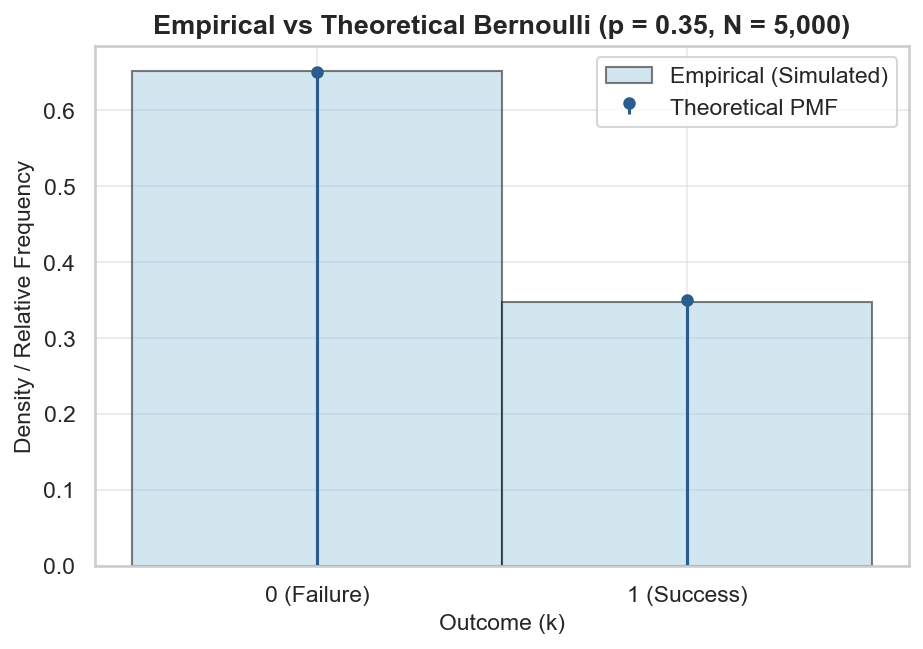

Theoretical p: 0.3500    |  Sample Proportion (p̂): 0.3478
Theoretical Var: 0.2275  |  Sample Var: 0.2269


In [9]:
from utils.plotting import plot_sample_vs_theory

# Parameters
p_true = 0.35
N_samples = 5000

# Generate pseudo-random Bernoulli samples
samples = stats.bernoulli.rvs(p_true, size=N_samples, random_state=42)

# Theoretical coordinates
k_support = np.array([0, 1])
pmf_theory = stats.bernoulli.pmf(k_support, p_true)

# Plot empirical vs theoretical
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_sample_vs_theory(
    samples=samples,
    x_theory=k_support,
    y_theory=pmf_theory,
    is_discrete=True,
    title=f"Empirical vs Theoretical Bernoulli (p = {p_true}, N = {N_samples:,})",
    xlabel="Outcome (k)",
    ax=ax,
)
ax.set_xticks([0, 1])
ax.set_xticklabels(["0 (Failure)", "1 (Success)"])
plt.show()

# Empirical checks
print(f"Theoretical p: {p_true:.4f}    |  Sample Proportion (p̂): {np.mean(samples):.4f}")
print(
    f"Theoretical Var: {p_true*(1-p_true):.4f}  |  Sample Var: {np.var(samples, ddof=1):.4f}"
)

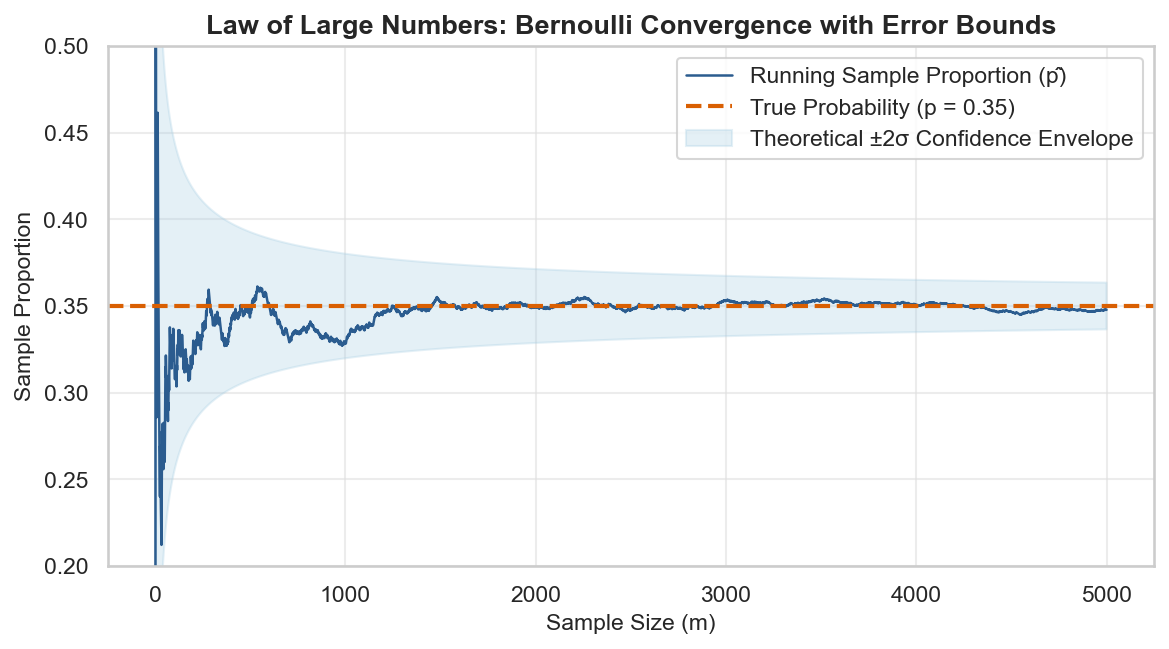

In [10]:
# Compute sequential running mean
m_indices = np.arange(1, N_samples + 1)
running_p = np.cumsum(samples) / m_indices

# Theoretical standard error envelope: ± 2 * SE
se_envelope = np.sqrt(p_true * (1 - p_true) / m_indices)

plt.figure(figsize=(9, 4.5))
plt.plot(
    m_indices,
    running_p,
    color=PALETTE["primary"],
    linewidth=1.2,
    label="Running Sample Proportion (p̂)",
)
plt.axhline(
    p_true,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"True Probability (p = {p_true})",
)

# Shaded 95% theoretical confidence envelope
plt.fill_between(
    m_indices,
    p_true - 2 * se_envelope,
    p_true + 2 * se_envelope,
    color=PALETTE["fill"],
    alpha=0.3,
    label="Theoretical ±2σ Confidence Envelope",
)

plt.title("Law of Large Numbers: Bernoulli Convergence with Error Bounds")
plt.xlabel("Sample Size (m)")
plt.ylabel("Sample Proportion")
plt.ylim(p_true - 0.15, p_true + 0.15)
plt.legend(frameon=True, loc="upper right")
plt.show()


## 6. Applied Real-World Use Case: A/B Testing & Sample Size Determination

### Scenario
An e-commerce company wants to test a new checkout button.
- **Control (A)**: Baseline conversion rate $p_A = 0.12$ (12%).
- **Variant (B)**: Redesigned button expected to achieve $p_B = 0.14$ (14%).
- **Absolute Lift ($\delta$)**: $p_B - p_A = 0.02$ (a +2 percentage point lift).

Each visitor's decision is a Bernoulli trial: $X_A \sim \text{Bernoulli}(p_A)$ and $X_B \sim \text{Bernoulli}(p_B)$.

### The Sample Size Problem
How many visitors $N$ must be routed to each version to reliably detect this lift?
Using the standard normal approximation for a two-tailed test with significance $\alpha = 0.05$ (95% confidence, $z_{\alpha/2} = 1.96$) and statistical power $1 - \beta = 0.80$ (80% power, $z_{\beta} = 0.84$):

$$N \approx \frac{(z_{\alpha/2} + z_{\beta})^2 \cdot \Big[ p_A(1 - p_A) + p_B(1 - p_B) \Big]}{(p_B - p_A)^2}$$

Notice the Bernoulli variances $p(1 - p)$ directly determine how much traffic is needed!


In [11]:
# A/B testing parameters
p_A = 0.12  # Baseline conversion rate
p_B = 0.14  # Target conversion rate (2% absolute lift)
delta = p_B - p_A

alpha = 0.05  # Significance level (5%)
power = 0.80  # Statistical power (80%)

# Critical z-values
z_alpha = stats.norm.ppf(1 - alpha / 2)  # ≈ 1.96
z_beta = stats.norm.ppf(power)  # ≈ 0.84

# Combined Bernoulli variances
pooled_var = (p_A * (1 - p_A)) + (p_B * (1 - p_B))

# Required sample size per variant
N_required = int(np.ceil(((z_alpha + z_beta) ** 2 * pooled_var) / (delta**2)))

print("--- A/B TEST SAMPLE SIZE REQUIREMENTS ---")
print(f"Control Conversion (p_A):  {p_A * 100:.1f}% (Var = {p_A * (1 - p_A):.4f})")
print(f"Variant Conversion (p_B):  {p_B * 100:.1f}% (Var = {p_B * (1 - p_B):.4f})")
print(f"Minimum Detectable Lift:   +{delta * 100:.1f}%")
print(f"Required Sample Size / Arm: {N_required:,} visitors")
print(f"Total Experiment Traffic:   {2 * N_required:,} visitors")

--- A/B TEST SAMPLE SIZE REQUIREMENTS ---
Control Conversion (p_A):  12.0% (Var = 0.1056)
Variant Conversion (p_B):  14.0% (Var = 0.1204)
Minimum Detectable Lift:   +2.0%
Required Sample Size / Arm: 4,435 visitors
Total Experiment Traffic:   8,870 visitors


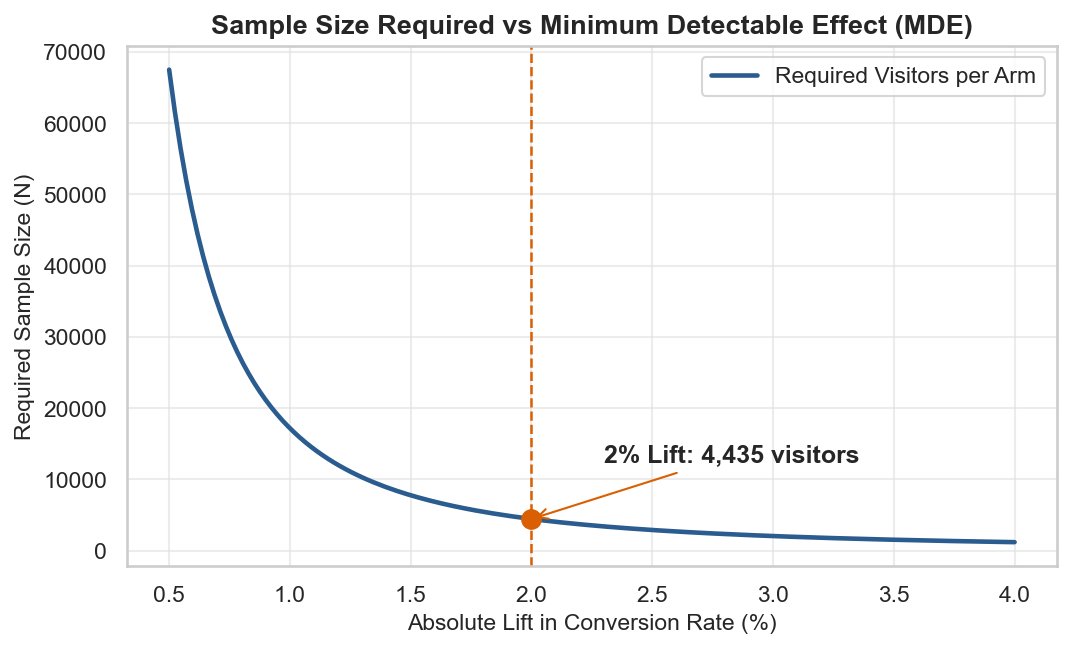

In [12]:
# Range of potential lifts to detect: from 0.5% to 4.0%
lifts = np.linspace(0.005, 0.04, 150)
p_variants = p_A + lifts

# Calculate required N for each lift
sample_sizes = [
    np.ceil(
        ((z_alpha + z_beta) ** 2 * (p_A * (1 - p_A) + pv * (1 - pv))) / (lift**2)
    )
    for lift, pv in zip(lifts, p_variants)
]

plt.figure(figsize=(8, 4.5))
plt.plot(
    lifts * 100,
    sample_sizes,
    color=PALETTE["primary"],
    linewidth=2.2,
    label="Required Visitors per Arm",
)

# Highlight our specific 2% case
plt.scatter([delta * 100], [N_required], color=PALETTE["secondary"], s=80, zorder=5)
plt.axvline(delta * 100, color=PALETTE["secondary"], linestyle="--", linewidth=1.2)
plt.annotate(
    f"2% Lift: {N_required:,} visitors",
    xy=(delta * 100, N_required),
    xytext=(delta * 100 + 0.3, N_required + 8000),
    arrowprops=dict(arrowstyle="->", color=PALETTE["secondary"]),
    weight="bold",
)

plt.title("Sample Size Required vs Minimum Detectable Effect (MDE)")
plt.xlabel("Absolute Lift in Conversion Rate (%)")
plt.ylabel("Required Sample Size (N)")
plt.legend(frameon=True)
plt.show()

## 7. Parameter Estimation (Maximum Likelihood Estimation - MLE)

Given a sample of $N$ binary observations $x_1, x_2, \dots, x_N \in \{0, 1\}$, how do we estimate the unknown success probability $p$?

### The Likelihood Function
The joint probability of observing this exact sequence is:
$$L(p) = \prod_{i=1}^{N} p^{x_i} (1 - p)^{1 - x_i} = p^{\sum x_i} (1 - p)^{N - \sum x_i}$$

### Log-Likelihood & Optimization
Taking the natural log converts the product into a sum:
$$\ln L(p) = \left(\sum_{i=1}^{N} x_i\right) \ln(p) + \left(N - \sum_{i=1}^{N} x_i\right) \ln(1 - p)$$

Differentiating with respect to $p$ and setting the derivative to zero:
$$\frac{d}{dp} \ln L(p) = \frac{\sum x_i}{p} - \frac{N - \sum x_i}{1 - p} = 0$$

Solving for $p$ yields the **analytical MLE**:
$$\hat{p}_{\text{MLE}} = \frac{1}{N}\sum_{i=1}^{N} x_i = \bar{x}$$
The maximum likelihood estimate for a Bernoulli parameter is simply the sample proportion of successes.


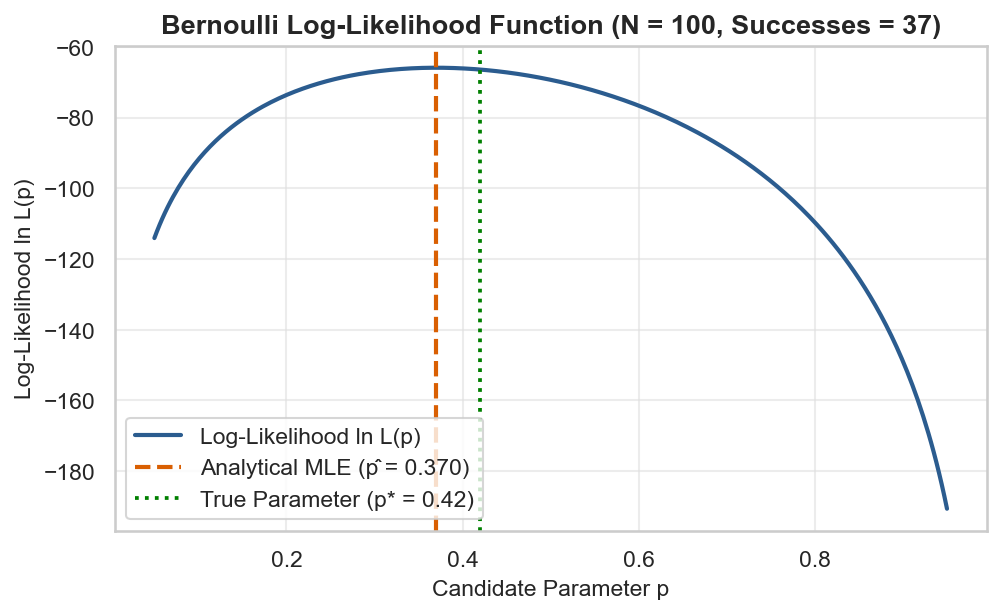

In [13]:
# True underlying probability
p_true = 0.42
N_obs = 100

# Generate synthetic binary observations
data = stats.bernoulli.rvs(p_true, size=N_obs, random_state=77)

# Analytical MLE: sample mean
p_mle_analytical = np.mean(data)
successes = np.sum(data)


# Bernoulli log-likelihood function
def bernoulli_log_lik(p_candidates, k_success, n_total):
    return k_success * np.log(p_candidates) + (n_total - k_success) * np.log(
        1 - p_candidates
    )


p_grid = np.linspace(0.05, 0.95, 300)
log_lik_values = bernoulli_log_lik(p_grid, successes, N_obs)

# Plot Log-Likelihood Curve
plt.figure(figsize=(7.5, 4.2))
plt.plot(
    p_grid,
    log_lik_values,
    color=PALETTE["primary"],
    linewidth=2,
    label="Log-Likelihood ln L(p)",
)
plt.axvline(
    p_mle_analytical,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Analytical MLE (p̂ = {p_mle_analytical:.3f})",
)
plt.axvline(
    p_true,
    color="green",
    linestyle=":",
    linewidth=1.8,
    label=f"True Parameter (p* = {p_true:.2f})",
)

plt.title(f"Bernoulli Log-Likelihood Function (N = {N_obs}, Successes = {successes})")
plt.xlabel("Candidate Parameter p")
plt.ylabel("Log-Likelihood ln L(p)")
plt.legend(frameon=True)
plt.show()

In [14]:
from scipy.optimize import minimize


# Negative log-likelihood objective function
def neg_log_lik(p, sample_data):
    p_val = np.clip(p[0], 1e-6, 1 - 1e-6)
    return -np.sum(stats.bernoulli.logpmf(sample_data, p_val))


# Minimize NLL starting from 0.5
res = minimize(neg_log_lik, x0=[0.5], args=(data,), bounds=[(1e-4, 0.9999)])
p_mle_num = res.x[0]

# Standard Error & 95% Wald Confidence Interval
se = np.sqrt(p_mle_num * (1 - p_mle_num) / N_obs)
ci_low = p_mle_num - 1.96 * se
ci_high = p_mle_num + 1.96 * se

print("--- BERNOULLI MLE RESULTS ---")
print(f"True Parameter (p*):        {p_true:.4f}")
print(f"Observed Successes:         {successes} / {N_obs}")
print(f"Analytical MLE (p̂):         {p_mle_analytical:.4f}")
print(f"Numerical MLE (Optimizer):  {p_mle_num:.4f}")
print(f"Standard Error (SE):        {se:.4f}")
print(f"95% Confidence Interval:    [{ci_low:.4f}, {ci_high:.4f}]")


--- BERNOULLI MLE RESULTS ---
True Parameter (p*):        0.4200
Observed Successes:         37 / 100
Analytical MLE (p̂):         0.3700
Numerical MLE (Optimizer):  0.3700
Standard Error (SE):        0.0483
95% Confidence Interval:    [0.2754, 0.4646]


## 8. Related Distributions & Summary

The Bernoulli distribution is the atomic seed of discrete probability:

1. **Binomial Distribution**:
   - The sum of $n$ independent and identically distributed Bernoulli trials:
     $$Y = \sum_{i=1}^{n} X_i \sim \text{Binomial}(n, p)$$
   - When $n = 1$, $\text{Binomial}(1, p) \equiv \text{Bernoulli}(p)$.

2. **Geometric Distribution**:
   - The number of Bernoulli trials required to achieve the **first** success:
     $$P(T = k) = (1 - p)^{k - 1} p \quad \text{for } k = 1, 2, \dots$$

3. **Negative Binomial Distribution**:
   - The number of failures before observing the **$r$-th** success in repeated Bernoulli trials.

4. **Categorical (Multinoulli) Distribution**:
   - Generalizes the Bernoulli distribution from $2$ outcomes to $K > 2$ discrete categories (e.g., rolling a 6-sided die).

5. **Beta Distribution (Bayesian Conjugacy)**:
   - In Bayesian inference, the **Beta distribution** is the conjugate prior for a Bernoulli likelihood.
   - If prior $p \sim \text{Beta}(\alpha, \beta)$ and we observe $k$ successes in $n$ trials, the posterior is simply $\text{Beta}(\alpha + k, \beta + n - k)$, naturally preventing the zero-frequency problem!


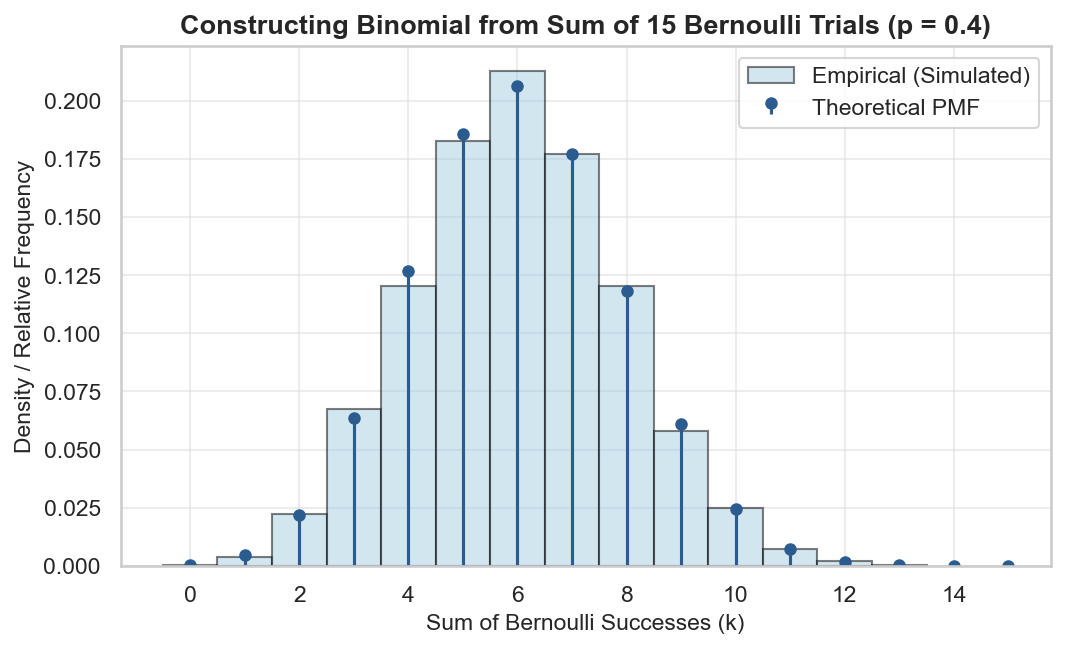

Mean of Sums:   6.010 (Theoretical n*p: 6.000)
Var of Sums:    3.589 (Theoretical n*p*(1-p): 3.600)


In [15]:
# Parameters
n_trials = 15
p_param = 0.4
N_reps = 10000

# 1. Generate matrix of pure independent Bernoulli trials: Shape (10000, 15)
bernoulli_matrix = stats.bernoulli.rvs(p_param, size=(N_reps, n_trials), random_state=42)

# 2. Sum along the columns to construct the composite variable: Y = sum(X_i)
binomial_sums = np.sum(bernoulli_matrix, axis=1)

# 3. Compare the sum of Bernoulli draws against theoretical Binomial(n=15, p=0.4)
k_axis = np.arange(0, n_trials + 1)
binom_pmf_theory = stats.binom.pmf(k_axis, n_trials, p_param)

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_sample_vs_theory(
    samples=binomial_sums,
    x_theory=k_axis,
    y_theory=binom_pmf_theory,
    is_discrete=True,
    title=f"Constructing Binomial from Sum of {n_trials} Bernoulli Trials (p = {p_param})",
    xlabel="Sum of Bernoulli Successes (k)",
    ax=ax,
)
plt.show()

print(f"Mean of Sums:   {np.mean(binomial_sums):.3f} (Theoretical n*p: {n_trials * p_param:.3f})")
print(f"Var of Sums:    {np.var(binomial_sums, ddof=1):.3f} (Theoretical n*p*(1-p): {n_trials * p_param * (1 - p_param):.3f})")

### Summary Card: Bernoulli Distribution

| Property | Formulation |
| :--- | :--- |
| **Notation** | $X \sim \text{Bernoulli}(p)$ |
| **Parameters** | $p \in [0, 1]$ (probability of success, $q = 1 - p$) |
| **Support** | $k \in \{0, 1\}$ |
| **PMF** | $P(X = k) = p^k (1 - p)^{1 - k}$ |
| **CDF** | $F(x) = \begin{cases} 0 & x < 0 \\ 1 - p & 0 \le x < 1 \\ 1 & x \ge 1 \end{cases}$ |
| **Mean ($\mu$)** | $p$ |
| **Variance ($\sigma^2$)** | $p(1 - p)$ |
| **Skewness ($\gamma_1$)** | $\frac{1 - 2p}{\sqrt{p(1 - p)}}$ |
| **Excess Kurtosis ($\gamma_2$)** | $\frac{1 - 6p(1 - p)}{p(1 - p)} = \frac{1}{p(1 - p)} - 6$ |
| **MLE Estimator** | $\hat{p} = \frac{1}{N}\sum_{i=1}^N x_i = \bar{x}$ |
| **Loss Function Link** | Negative Log-Likelihood $\equiv$ Binary Cross-Entropy (Log Loss) |
| **Key Use Cases** | A/B test conversion rates, click-through rates (CTR), default prediction, coin tosses |
